# Simulación
Modelo Euler-Lagrange: $M(q)\ddot q + C(q,\dot q)\dot q + g(q) + f(\dot q) = \tau$

Se integra en variables de estado $x=[q_1\;q_2\;\dot q_1\;\dot q_2]^T$ durante 10 s.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

## 1. Parámetros del robot

In [ ]:
g = 9.81
m1, m2 = 1.0, 1.0            # kg
l1, l2 = 0.5, 0.5            # m
lc1, lc2 = 0.25, 0.25        # m
I1 = m1*l1**2/12             # kg m^2 (barra delgada)
I2 = m2*l2**2/12
fv1, fv2 = 0.05, 0.05        # fricción viscosa  N m s/rad
fc1, fc2 = 0.02, 0.02        # fricción Coulomb  N m
eps = 1e-2                   # suavizado de sign() -> tanh(qd/eps)

## 2. Matrices del modelo

In [ ]:
def M_mat(q):
    q1, q2 = q
    c2 = np.cos(q2)
    M11 = m1*lc1**2 + m2*(l1**2 + lc2**2 + 2*l1*lc2*c2) + I1 + I2
    M12 = m2*(lc2**2 + l1*lc2*c2) + I2
    M22 = m2*lc2**2 + I2
    return np.array([[M11, M12],[M12, M22]])

def C_mat(q, qd):
    q1, q2 = q
    qd1, qd2 = qd
    h = -m2*l1*lc2*np.sin(q2)
    return np.array([[h*qd2, h*(qd1+qd2)],
                     [-h*qd1, 0.0]])

def g_vec(q):
    q1, q2 = q
    g1 = (m1*lc1 + m2*l1)*g*np.cos(q1) + m2*lc2*g*np.cos(q1+q2)
    g2 = m2*lc2*g*np.cos(q1+q2)
    return np.array([g1, g2])

def f_vec(qd):
    return np.array([fv1*qd[0] + fc1*np.tanh(qd[0]/eps),
                     fv2*qd[1] + fc2*np.tanh(qd[1]/eps)])

## 3. Pares de los motores
Por defecto $\tau=0$ (el robot cae por gravedad y la fricción lo va frenando).


In [ ]:
def tau_fun(t, q, qd):
    return np.array([0.0, 0.0])

# Ejemplos:
# return np.array([0.5, 0.0])                       # par constante en la articulación 1
# return np.array([0.3*np.sin(2*t), 0.1*np.cos(2*t)])
# PD + compensación de gravedad hacia q_d = [pi/2, 0]:
#   qdes = np.array([np.pi/2, 0.0]); Kp = np.array([20, 10]); Kd = np.array([5, 2])
#   return Kp*(qdes-q) - Kd*qd + g_vec(q)

## 4. Dinámica en variables de estado

In [ ]:
def dynamics(t, x):
    q, qd = x[:2], x[2:]
    tau = tau_fun(t, q, qd)
    qdd = np.linalg.solve(M_mat(q), tau - C_mat(q, qd) @ qd - g_vec(q) - f_vec(qd))
    return np.concatenate([qd, qdd])

x0 = [np.pi/3, np.pi/6, 0.0, 0.0]       # q1, q2, dq1, dq2 iniciales
T = 10.0
t_eval = np.linspace(0, T, 1001)         # 100 puntos por segundo

sol = solve_ivp(dynamics, (0, T), x0, t_eval=t_eval, method='LSODA', rtol=1e-8, atol=1e-10)
t = sol.t
q1, q2, dq1, dq2 = sol.y
print(sol.message)

The solver successfully reached the end of the integration interval.


## 5. Posición de las articulaciones y del efector

In [ ]:
x1 = l1*np.cos(q1);              y1 = l1*np.sin(q1)                  # articulación 2 (codo)
xe = x1 + l2*np.cos(q1+q2);      ye = y1 + l2*np.sin(q1+q2)          # efector

## 6. Gráficas

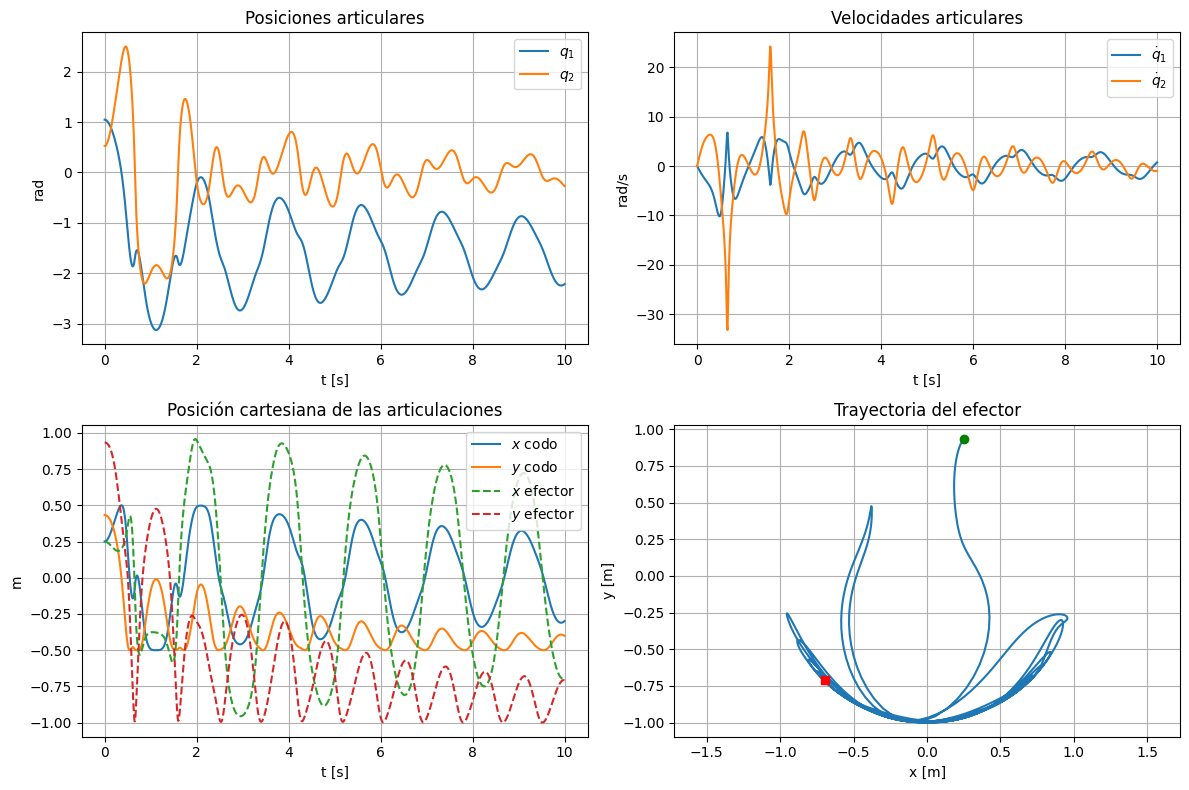

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0,0].plot(t, q1, label='$q_1$'); ax[0,0].plot(t, q2, label='$q_2$')
ax[0,0].set(title='Posiciones articulares', xlabel='t [s]', ylabel='rad'); ax[0,0].legend(); ax[0,0].grid()

ax[0,1].plot(t, dq1, label='$\\dot q_1$'); ax[0,1].plot(t, dq2, label='$\\dot q_2$')
ax[0,1].set(title='Velocidades articulares', xlabel='t [s]', ylabel='rad/s'); ax[0,1].legend(); ax[0,1].grid()

ax[1,0].plot(t, x1, label='$x$ codo'); ax[1,0].plot(t, y1, label='$y$ codo')
ax[1,0].plot(t, xe, '--', label='$x$ efector'); ax[1,0].plot(t, ye, '--', label='$y$ efector')
ax[1,0].set(title='Posición cartesiana de las articulaciones', xlabel='t [s]', ylabel='m'); ax[1,0].legend(); ax[1,0].grid()

ax[1,1].plot(xe, ye); ax[1,1].plot(xe[0], ye[0], 'go'); ax[1,1].plot(xe[-1], ye[-1], 'rs')
ax[1,1].set(title='Trayectoria del efector', xlabel='x [m]', ylabel='y [m]'); ax[1,1].axis('equal'); ax[1,1].grid()
plt.tight_layout(); plt.show()

## 7. Animación del robot

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
R = l1 + l2 + 0.1
ax.set(xlim=(-R, R), ylim=(-R, R), aspect='equal', xlabel='x [m]', ylabel='y [m]')
ax.grid(); ax.axhline(0, color='k', lw=3)
line, = ax.plot([], [], 'o-', lw=4, color='tab:blue', markersize=8)
trace, = ax.plot([], [], '-', lw=1, color='tab:red', alpha=0.6)
txt = ax.text(0.02, 0.95, '', transform=ax.transAxes)

step = 10  # 1 de cada 10 muestras -> 10 fps
frames = range(0, len(t), step)

def update(i):
    line.set_data([0, x1[i], xe[i]], [0, y1[i], ye[i]])
    trace.set_data(xe[:i+1], ye[:i+1])
    txt.set_text(f't = {t[i]:.2f} s')
    return line, trace, txt

anim = FuncAnimation(fig, update, frames=frames, interval=100, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

In [ ]:
anim.save('simulacion_robot_2gdl.gif', writer=PillowWriter(fps=10))
print('GIF guardado')

GIF guardado
